## A/B Test Analysis

**Objective:** Analyze the results of an A/B test conducted in the popular [Cookie Cats game](https://www.facebook.com/cookiecatsgame). Cookie Cats is a match-three puzzle game in which players connect tiles of the same color to clear the board and complete levels. The game also features singing cats :)

As players progress through the game, they encounter gates that require them to wait for a certain period before they can continue playing or make in-app purchases.

In this project, we analyze the results of an A/B test in which the first gate in Cookie Cats was moved from level 30 to level 40. Specifically, we aim to understand how this change affected player retention — whether moving the gate 10 levels later influenced how soon or how late players stopped playing, measured by the number of days since installing the game.

The analysis is based on the `cookie_cats.csv` [dataset](https://drive.google.com/file/d/145Pa5VfhJ-dglk8-Wn9Ade866s7hCPiP/view?usp=sharing), which contains the following columns:

- `userid` — a unique identifier assigned to each player.
- `version` — indicates whether a player was assigned to the control group (`gate_30`, with the gate at level 30) or the treatment group (`gate_40`, with the gate at level 40).
- `sum_gamerounds` — the total number of game rounds played by a player during the first week after installation.
- `retention_1` — indicates whether the player returned to the game and played again one day after installation.
- `retention_7` — indicates whether the player returned to the game and played again seven days after installation.

Upon installing the game, each player was randomly assigned to either the `gate_30` or `gate_40` group.

In [1]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.stats.api as sms
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil


%matplotlib inline

# 1. Sample Size

(In case we needed to design an experiment)

First, let’s assume that we are planning to conduct the A/B test and want to determine how many users we need to collect data from to detect a meaningful effect. We define a meaningful effect as a 1 percentage point increase in retention following the change. Let’s calculate the total sample size required to detect this effect, given that the Product Manager has indicated a baseline retention rate of 19%.

In [3]:
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

p_base = 0.19         # baseline retention rate
p_target = 0.20       # +1 pp - expected retention rate
alpha = 0.05          # significance level
power = 0.8           # statistical power of 80%

effect_size = sms.proportion_effectsize(p_target, p_base)   # Cohen's h effect size

n_per_group = sms.NormalIndPower().solve_power(             # calculate the required sample size
    effect_size=effect_size,
    alpha=alpha,
    power=power,
    ratio=1,                                                # both groups have equal sample sizes: 1:1 allocation
    alternative='two-sided'
)


n_per_group = ceil(n_per_group)                             # round up to the nearest integer

print(f"Effect size (h): {effect_size:.4f}")
print(f"Required sample size per group: {n_per_group}")
print(f"Total required sample size: {2 * n_per_group}")

Effect size (h): 0.0252
Required sample size per group: 24638
Total required sample size: 49276


Therefore, we need a minimum of **24,638 observations per group** (control and treatment), or **49,276 observations in total** across both groups.

A **statistical power of 0.8 (80%)** means that if the true difference in retention rates is 1 percentage point (19% vs. 20%), the calculated sample size gives us an 80% probability of detecting this difference as statistically significant.

# 2. Hypotheses
Let's load the A/B test data into the `df` variable and print the mean value of the `retention_7` metric (7-day retention) across the game versions. Let's formulate a hypothesis: which version provides better retention 7 days after game installation?

In [4]:
df = pd.read_csv('/content/drive/MyDrive/1. IT study/Data Loves Academy/Data Analyst/15. Модуль 15/homeworks/cookie_cats.csv')

df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


In [6]:
# Checking if each userid appears only once
df['userid'].is_unique

True

In [7]:
# Number of players in each group
df['version'].value_counts()

,count
version,
gate_40,45489
gate_30,44700


In [8]:
counts = df['version'].value_counts()

print(counts)
print("Number of groups:", df['version'].nunique())
print("The sum of unique users in the groups is equal to the total number of rows:", counts.sum() == len(df))

version
gate_40    45489
gate_30    44700
Name: count, dtype: int64
Number of groups: 2
The sum of unique users in the groups is equal to the total number of rows: True


Therefore, the initial group size distribution appears balanced.

In [9]:
# The mean value of the retention_7 metric across game versions

df.groupby("version")["retention_7"].mean()

,retention_7
version,
gate_30,0.190201
gate_40,0.182000


**Overall hypotheses:**

- $H_0: p_{\text{gate_30}} = p_{\text{gate_40}} $  — the game version does not affect Day 7 Retention.
- $H_a: p_{\text{gate_30}} \neq p_{\text{gate_40}} $  — the game version affects Day 7 Retention.

In general, we want to test whether moving the gate from level 30 to level 40 **improves** retention. Therefore, we could also formulate the alternative hypothesis as:

- $H_a: p_{\text{gate_30}} < p_{\text{gate_40}}$

This reflects our initial expectation that Day 7 Retention would be higher for `gate_40` than for `gate_30`.

🔹🔹🔹 However, the A/B test sample results and the calculated mean retention rates suggest the opposite: the control group (`gate_30`) has a slightly higher retention rate. Therefore, we can preliminarily assume that it performs better in terms of retention:

$$
19.02\% - 18.20\% = 0.82\text{ p.p.}
$$

In other words, the control group has a Day 7 Retention rate that is 0.82 percentage points higher than that of the treatment group.

🔹🔹🔹 **Hypothesis at this stage:**

Based on the observed mean values, we can preliminarily assume that moving the gate from level 30 to level 40 **did not improve** player retention.

To confirm this assumption, we need to test whether the observed difference is statistically significant.

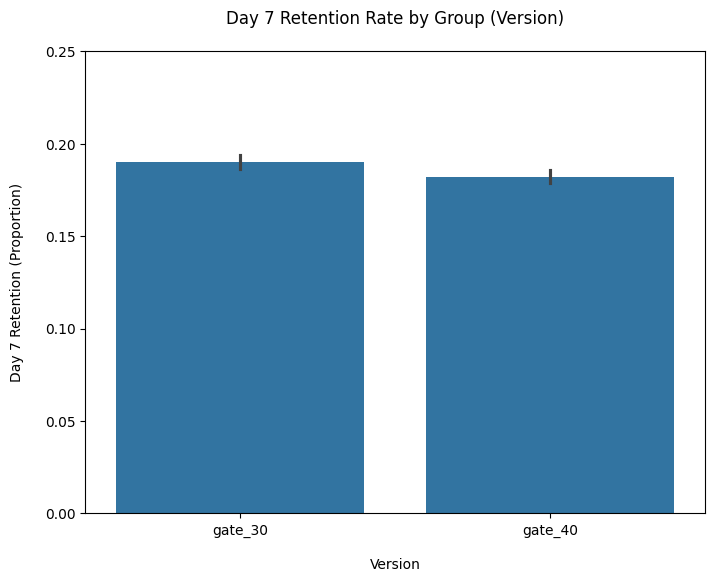

In [10]:
plt.figure(figsize=(8,6))

sns.barplot(x=df['version'], y=df['retention_7'])

plt.ylim(0, 0.25)
plt.title('Day 7 Retention Rate by Group (Version)', pad=20)
plt.xlabel('Version', labelpad=15)
plt.ylabel('Day 7 Retention (Proportion)', labelpad=15);

# 3. Z-test
Since we have a large sample, we can use the normal approximation to calculate our $p$-value to test the statistical significance of the difference — that is, a Z-test for proportions.
The significance level set for this task is $0.05$.
We also calculate confidence intervals for the variants before and after moving the gate. Finally, we will formulate conclusions.

In [11]:
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

# Split data into control and treatment groups
control = df[df['version'] == 'gate_30']['retention_7']
treatment = df[df['version'] == 'gate_40']['retention_7']

# Number of "successes" - number of users who returned on day 7
# The .sum() method counts the number of True values
successes = np.array([control.sum(), treatment.sum()])

# Total number of users in each group
nobs = np.array([len(control), len(treatment)])


# Z-test for two proportions
z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=nobs,
    alternative='two-sided')


# 95% Confidence intervals
ci_control = proportion_confint(
                          count=successes[0],
                          nobs=nobs[0],
                          alpha=0.05,
                          method='normal')

ci_treatment = proportion_confint(
                          count=successes[1],
                          nobs=nobs[1],
                          alpha=0.05,
                          method='normal')


print(f"z statistic: {z_stat:.4f}")
print(f"p-value: {p_value:.4f}")
print(f"95% Confidence Interval for control group: [{ci_control[0]:.4f}, {ci_control[1]:.4f}]")
print(f"95% Confidence Interval for treatment group: [{ci_treatment[0]:.4f}, {ci_treatment[1]:.4f}]")

z statistic: 3.1644
p-value: 0.0016
95% Confidence Interval for control group: [0.1866, 0.1938]
95% Confidence Interval for treatment group: [0.1785, 0.1855]


**Conclusions:**

- The obtained $p$-value $= 0.0016 < α = 0.05$, so we **reject the null hypothesis $H_0$**.

   The difference in `retention_7` between the two groups is statistically significant. The control group (`gate_30`) has a higher retention rate (19.02%) than the treatment group (`gate_40`) (18.20%). Therefore, moving the gate from level 30 to level 40 is associated with a decrease in retention of approximately **0.82 percentage points**.

- **The confidence intervals do not overlap:**

   - `control`: [0.1866, 0.1938]
   - `treatment`: [0.1785, 0.1855]

   The upper bound of the `treatment` confidence interval (0.1855) is below the lower bound of the `control` confidence interval (0.1866). This is consistent with the Z-test result, indicating that the difference between the two versions is unlikely to be due to random variation.

   In addition, the confidence interval for the `treatment` group does not include the target retention rate of 20%. This provides further evidence that moving the gate from level 30 to level 40 is unlikely to improve user retention.

   However, non-overlapping confidence intervals for individual groups are not a universal criterion for statistical significance. We rely directly on the result of the Z-test to assess the statistical significance of the difference.

# 4. **Chi-square test**
    
We run a Сhi-square test at the 5% significance level to determine whether there is a association between the game version and player retention on day 7 after installation.

- Formulate the hypotheses.
- Perform the calculations, output the p-value and write a conclusion based on the test results.

The Chi-square test of independence is used to check for a statistical association between two categorical variables.

In our case, these are:

- `version`: the game version (`gate_30` or `gate_40`);
- `retention_7`: user return on Day 7 (`True` or `False`).

**Hypotheses**:

- $H_0$: The game version and Day 7 Retention rate are independent of each other.
- $H_1$: There is a statistically significant association between the game version and Day 7 Retention rate.

Significance level: $\alpha = 0.05$.

In [12]:
from scipy.stats import chi2_contingency

# Сontingency table
contingency_table = pd.crosstab(
    df['version'],
    df['retention_7']
)

display(contingency_table)

# Chi-square test
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)

print(f'Chi-square statistic: χ² = {chi2:.4f}')
print(f'p-value: {p_value:.4f}')
print(f'Degrees of freedom (ступені свободи): {dof}')

if p_value < alpha:
    print("Reject H0: Game version and Day 7 Retention rate are associated")
else:
    print("Fail to reject H0: No significant relationship detected")

retention_7,False,True
version,,
gate_30,36198,8502
gate_40,37210,8279


Chi-square statistic: χ² = 9.9591
p-value: 0.0016
Degrees of freedom (ступені свободи): 1
Reject H0: Game version and Day 7 Retention rate are associated


The obtained $p$-value $= 0.0016 < \alpha = 0.05$. Therefore, we reject $H_0$.

Thus, there is a statistically significant association between the game version and user retention on Day 7. The game version with the gate at level 30 demonstrates higher user retention compared to the version with the gate moved to level 40.

The Chi-square test result is consistent with the Z-test findings.

# Conclusions

Moving the first gate in Cookie Cats from level 30 to level 40 did not improve user retention. On the contrary, the treatment group demonstrated a lower Day 7 Retention rate compared to the control group ($18.20\%$ vs. $19.02\%$).

Both the Z-test and the Chi-square test confirmed that this difference is statistically significant ($p$-value $< \alpha = 0.05$).

Thus,  based on the experimental results, there is no empirical evidence to support moving the gate from level 30 to level 40 as a way to improve user retention. Instead, the findings support retaining the original gate placement at level 30.